# Módulo 2: predicción de casos de dengue con SimpleRNN y LSTM

Con el clima y los casos de las últimas 26 semanas, pronostica los casos de las próximas 4 semanas. Como pide el enunciado, comparamos dos redes:

- **SimpleRNN (modelo base):** secciones 7 a 9.
- **LSTM (modelo principal):** secciones 10 y 11, con los mismos datos, el mismo split, las mismas semillas y las mismas métricas.

Se basa en los notebooks de clase *RNN-Forecast ventas* y *RNN-Forecast Temperatura* (`TimeseriesGenerator`, `MinMaxScaler`, LSTM, EarlyStopping y RMSE).

**Requerido por el enunciado, no visto en clase:** SimpleRNN; dos capas LSTM apiladas (`return_sequences=True`) con Dropout; varias variables de entrada y salida de 4 semanas (en clase: una variable y una semana); seno y coseno de la semana para usar las fechas; baseline estacional y MAE.

**Extras nuestros, no vistos en clase:** validación separada del test (en clase se validaba con el test), `restore_best_weights` en EarlyStopping, el control de persistencia y repetir con varias semillas.

# 1. Importación librerías

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"   # para que los resultados se puedan repetir

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow

# 2. Importación fuente de datos

In [2]:
# Usamos el archivo que dejó el EDA: casos reales, clima y log_casos
df = pd.read_csv("../data/processed/dengue_procesado.csv",
                 parse_dates=["fecha_inicio_semana"], index_col="fecha_inicio_semana")
print(df.shape)
print(df.index.min().date(), "a", df.index.max().date())
df[["casos_dengue", "log_casos", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].head()

(566, 25)
2014-02-23 a 2024-12-22


,casos_dengue,log_casos,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,
2014-02-23,96,4.574711,3.3,29.8,19.7,68.1
2014-03-02,75,4.330733,4.6,29.9,20.3,68.0
2014-03-09,94,4.553877,2.3,30.7,19.8,65.3
2014-03-16,71,4.276666,4.7,31.2,20.7,65.7
2014-03-23,95,4.564348,6.5,31.5,21.1,65.8


# 3. EDA + Preprocesado

El EDA completo está en `01_EDA.ipynb`. Lo que usamos de ahí:

- Los casos tienen brotes muy grandes, así que entrenamos con `log_casos`.
- El clima actúa con retraso. Una ventana de 26 semanas ya contiene el clima de hace 2, 4, 6 y 8 semanas; en la sección 8.1 revisamos si además conviene dar los lags como columnas.
- El enunciado pide usar las fechas. Convertimos la semana del año en seno y coseno para que la semana 52 quede pegada a la semana 1 (las 2 semanas 53 de los datos caen en el mismo punto que la semana 1).

In [3]:
df["semana_sin"] = np.sin(2 * np.pi * df["semana_epi"] / 52)
df["semana_cos"] = np.cos(2 * np.pi * df["semana_epi"] / 52)

clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
lags = [columna for columna in df.columns if "_lag" in columna]

columnas_base = ["log_casos"] + clima + ["semana_sin", "semana_cos"]
columnas_con_lags = columnas_base + lags
print(len(columnas_base), "variables base;", len(columnas_con_lags), "con lags")

7 variables base; 23 con lags


# 4. Train/Test

Es una serie de tiempo, así que el corte es temporal:

- **Test:** las últimas 104 semanas (2023-2024).
- **Validación:** las últimas 52 semanas de train (2022). Sirve para EarlyStopping, para elegir variables (8.1) y para elegir entre SimpleRNN y LSTM (10.2); el test no se usa para decidir nada.
- **Train:** todo lo anterior.

Cada ventana de entrada tiene 26 semanas y el objetivo son las 4 semanas siguientes. Las 4 semanas objetivo quedan siempre completas dentro de su propio grupo.

In [4]:
VENTANA = 26     # semanas de entrada
HORIZONTE = 4    # semanas a pronosticar
SEMANAS_TEST = 104
SEMANAS_VALIDACION = 52

n_total = len(df)
inicio_test = n_total - SEMANAS_TEST
inicio_validacion = inicio_test - SEMANAS_VALIDACION

print("Train: hasta", df.index[inicio_validacion - 1].date())
print("Validación:", df.index[inicio_validacion].date(), "a", df.index[inicio_test - 1].date())
print("Test:", df.index[inicio_test].date(), "a", df.index[-1].date())

Train: hasta 2021-12-26
Validación: 2022-01-02 a 2022-12-25
Test: 2023-01-01 a 2024-12-22


# 5. Escalado

In [5]:
from sklearn.preprocessing import MinMaxScaler

In [6]:
# Solo utilizamos datos anteriores al test para ajustar el escalado; si no, estaríamos usando información del test
escalador_y = MinMaxScaler()
escalador_y.fit(df[["log_casos"]].values[:inicio_test])
y_escalado = escalador_y.transform(df[["log_casos"]].values).ravel()

In [7]:
# Objetivos: en la fila i están las 4 semanas que empiezan en i
objetivos = np.full((n_total, HORIZONTE), np.nan)
casos_reales = np.full((n_total, HORIZONTE), np.nan)
for i in range(n_total - HORIZONTE + 1):
    objetivos[i] = y_escalado[i:i + HORIZONTE]
    casos_reales[i] = df["casos_dengue"].values[i:i + HORIZONTE]

filas_validacion = np.arange(inicio_validacion, inicio_test - HORIZONTE + 1)
filas_test = np.arange(inicio_test, n_total - HORIZONTE + 1)

# 6. Creación Generador Serie Temporal

Como en clase, usamos `TimeseriesGenerator` para cortar la serie en ventanas: 26 semanas de entrada y, como objetivo, las 4 semanas siguientes.

Lo dejamos dentro de una función porque en la sección 8.1 se preparan los datos con dos listas de variables distintas (con y sin lags).

In [8]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [9]:
# Escala las columnas y crea los generadores de train, validación y test
def preparar_datos(columnas):
    escalador_X = MinMaxScaler()
    escalador_X.fit(df[columnas].values[:inicio_test])
    X = escalador_X.transform(df[columnas].values)

    generador = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=16,
                                    start_index=0, end_index=inicio_validacion - HORIZONTE)
    val_generador = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=64,
                                        start_index=inicio_validacion - VENTANA, end_index=inicio_test - HORIZONTE)
    test_generador = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=64,
                                         start_index=inicio_test - VENTANA, end_index=n_total - HORIZONTE)
    return X, escalador_X, generador, val_generador, test_generador


# Pasa una predicción escalada a casos reales: quita el escalado y el logaritmo
def a_casos(prediccion_escalada):
    log_casos = escalador_y.inverse_transform(prediccion_escalada.reshape(-1, 1))
    return np.expm1(log_casos).reshape(-1, HORIZONTE).clip(min=0)

In [10]:
# ¿Qué obtenemos del primer batch?
_, _, generador_ejemplo, _, _ = preparar_datos(columnas_base)
X_lote, y_lote = generador_ejemplo[0]
print("Entrada:", X_lote.shape, "-> (ventanas del lote, 26 semanas, variables)")
print("Objetivo:", y_lote.shape, "-> (ventanas del lote, 4 semanas)")
print("Ventanas de validación:", len(filas_validacion), " Ventanas de test:", len(filas_test))

Entrada: (16, 26, 7) -> (ventanas del lote, 26 semanas, variables)
Objetivo: (16, 4) -> (ventanas del lote, 4 semanas)
Ventanas de validación: 49  Ventanas de test: 101


# 7. Creación del modelo

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM, Dropout

In [12]:
# Definimos el modelo. "SimpleRNN" es el modelo base y "LSTM" el modelo principal (sección 10)
def crear_modelo(n_variables, tipo="SimpleRNN"):
    model = Sequential()
    model.add(Input(shape=(VENTANA, n_variables)))   # 26 semanas x n variables
    if tipo == "SimpleRNN":
        model.add(SimpleRNN(32))
    else:
        model.add(LSTM(64, return_sequences=True))   # pasa las 26 semanas completas a la siguiente LSTM
        model.add(LSTM(32))
        model.add(Dropout(0.2))
    model.add(Dense(HORIZONTE))   # una neurona de salida por cada una de las 4 semanas
    model.compile(optimizer='adam', loss='mse')
    return model

In [13]:
crear_modelo(len(columnas_base)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,412 (5.52 KB)

 Trainable params: 1,412 (5.52 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Entrenamiento del modelo

In [14]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [15]:
# Entrena una red completa con una semilla. Solo se usa donde hay que repetir con varias semillas (8.1, 9.1 y 10.2)
def entrenar(columnas, semilla, tipo="SimpleRNN"):
    tf.keras.utils.set_random_seed(semilla)
    X, escalador_X, generador, val_generador, test_generador = preparar_datos(columnas)
    model = crear_modelo(len(columnas), tipo)
    early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
    model.fit(generador, epochs=200, validation_data=val_generador, callbacks=[early_stop], verbose=0)
    return model, model.history, X, escalador_X, val_generador, test_generador


# Métricas en casos reales, con las funciones de sklearn
def rmse(real, prediccion):
    return np.sqrt(mean_squared_error(real, prediccion))


def mae(real, prediccion):
    return mean_absolute_error(real, prediccion)

## 8.1 ¿Conviene agregar los lags como columnas?

Comparamos solo con validación, repitiendo con 3 semillas porque una red cambia de una corrida a otra.

In [16]:
resultados = []
for nombre, columnas in [("Sin lags", columnas_base), ("Con lags", columnas_con_lags)]:
    for semilla in [101, 1, 2]:
        modelo, _, _, _, validacion, _ = entrenar(columnas, semilla)
        prediccion = a_casos(modelo.predict(validacion, verbose=0))
        resultados.append({"variables": nombre, "semilla": semilla,
                           "RMSE_validacion": rmse(casos_reales[filas_validacion], prediccion)})

comparacion = pd.DataFrame(resultados)
print(comparacion.pivot(index="semilla", columns="variables", values="RMSE_validacion").round(1))
print(comparacion.groupby("variables")["RMSE_validacion"].mean().round(1))

variables  Con lags  Sin lags
semilla                      
1              42.6      42.5
2              40.9      37.2
101            45.2      35.1
variables
Con lags    42.9
Sin lags    38.3
Name: RMSE_validacion, dtype: float64


Elegimos las variables con menor error promedio en validación. La ventana de 26 semanas ya contiene el clima de esos lags, y con 16 columnas más el modelo tiene más pesos que aprender con los mismos pocos datos.

## 8.2 Entrenamiento del modelo final

In [17]:
promedios = comparacion.groupby("variables")["RMSE_validacion"].mean()
columnas_finales = columnas_base if promedios["Sin lags"] <= promedios["Con lags"] else columnas_con_lags
print("Variables elegidas:", columnas_finales)

Variables elegidas: ['log_casos', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct', 'semana_sin', 'semana_cos']


In [18]:
tf.keras.utils.set_random_seed(101)   # la misma semilla en todo el notebook
X, escalador_X, generador, gen_validacion, gen_test = preparar_datos(columnas_finales)

modelo_rnn = crear_modelo(len(columnas_finales))
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

modelo_rnn.fit(generador, epochs=200,
               validation_data=gen_validacion,
               callbacks=[early_stop], verbose=0)

Épocas entrenadas: 77


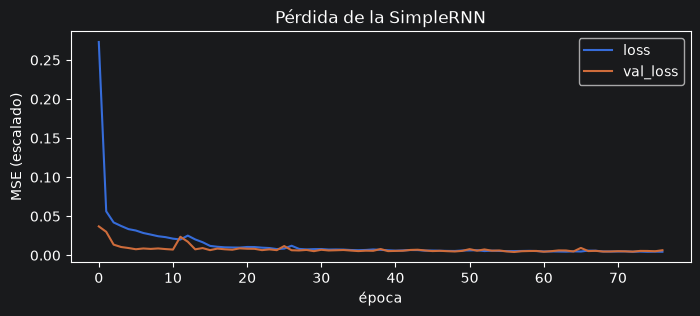

In [19]:
losses = pd.DataFrame(modelo_rnn.history.history)
print("Épocas entrenadas:", len(losses))

losses.plot(figsize=(8, 3), title="Pérdida de la SimpleRNN")
plt.xlabel("época")
plt.ylabel("MSE (escalado)")
plt.show()

# 9. Evaluación del modelo

Medimos en **casos reales**, no en logaritmo, sobre las 101 ventanas completas del test. Comparamos contra:

- **Baseline estacional (lo pide el enunciado):** la misma semana del año anterior.
- **Persistencia (control extra):** las próximas 4 semanas repiten los casos de la última semana conocida. Es el pronóstico más simple posible, y sirve para saber si la red aporta algo más que copiar el último dato.

In [20]:
prediccion_test = a_casos(modelo_rnn.predict(gen_test, verbose=0))
real_test = casos_reales[filas_test]
casos = df["casos_dengue"].values

estacional = np.array([casos[i - 52:i - 52 + HORIZONTE] for i in filas_test])
persistencia = np.array([[casos[i - 1]] * HORIZONTE for i in filas_test])

tabla = pd.DataFrame({
    "RMSE": [rmse(real_test, p) for p in (prediccion_test, estacional, persistencia)],
    "MAE": [mae(real_test, p) for p in (prediccion_test, estacional, persistencia)],
}, index=["SimpleRNN", "Baseline estacional", "Persistencia"]).round(1)
print(tabla)

mejora = 100 * (1 - tabla.loc["SimpleRNN"] / tabla.loc["Baseline estacional"])
print("Mejora de la SimpleRNN sobre el baseline estacional (%):")
print(mejora.round(1))

                      RMSE    MAE
SimpleRNN            260.2  174.9
Baseline estacional  638.3  455.7
Persistencia         215.8  141.3
Mejora de la SimpleRNN sobre el baseline estacional (%):
RMSE    59.2
MAE     61.6
dtype: float64


In [21]:
# Error según qué tan lejos es el pronóstico
por_semana = pd.DataFrame({
    "RMSE_SimpleRNN": [rmse(real_test[:, h], prediccion_test[:, h]) for h in range(HORIZONTE)],
    "RMSE_persistencia": [rmse(real_test[:, h], persistencia[:, h]) for h in range(HORIZONTE)],
}, index=[f"semana +{h + 1}" for h in range(HORIZONTE)]).round(1)
por_semana

,RMSE_SimpleRNN,RMSE_persistencia
semana +1,229.2,129.2
semana +2,219.5,189.7
semana +3,338.7,236.3
semana +4,235.3,278.7


In [22]:
# Error por año del test, según la primera semana pronosticada
# El sesgo es real menos pronóstico: si es positivo, el pronóstico se queda corto
anios = df.index[filas_test].year
por_anio = pd.DataFrame([{
    "año": anio,
    "RMSE_SimpleRNN": rmse(real_test[anios == anio], prediccion_test[anios == anio]),
    "RMSE_estacional": rmse(real_test[anios == anio], estacional[anios == anio]),
    "RMSE_persistencia": rmse(real_test[anios == anio], persistencia[anios == anio]),
    "sesgo_SimpleRNN": (real_test[anios == anio] - prediccion_test[anios == anio]).mean(),
    "sesgo_estacional": (real_test[anios == anio] - estacional[anios == anio]).mean(),
} for anio in [2023, 2024]]).set_index("año").round(1)
por_anio

,RMSE_SimpleRNN,RMSE_estacional,RMSE_persistencia,sesgo_SimpleRNN,sesgo_estacional
año,,,,,
2023,301.0,718.2,252.0,146.1,470.8
2024,206.1,536.5,166.9,85.9,-14.6


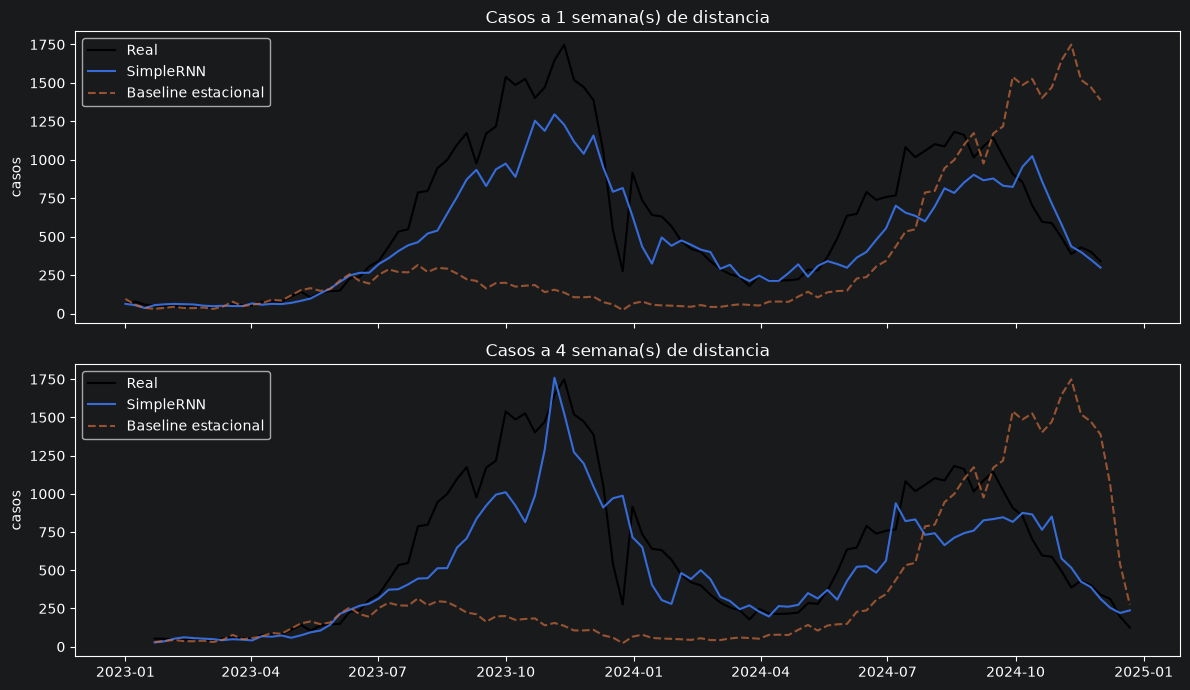

Semana del pico: 2023-11-12
Casos reales: 1749  Pronóstico a 1 semana: 1227


In [23]:
# Pronóstico contra lo real: a 1 semana y a 4 semanas
fechas = df.index

fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eje, h in zip(ejes, [0, 3]):
    fechas_objetivo = fechas[filas_test + h]
    eje.plot(fechas_objetivo, real_test[:, h], label="Real", color="black")
    eje.plot(fechas_objetivo, prediccion_test[:, h], label="SimpleRNN")
    eje.plot(fechas_objetivo, estacional[:, h], label="Baseline estacional", linestyle="--", alpha=0.7)
    eje.set_title(f"Casos a {h + 1} semana(s) de distancia")
    eje.set_ylabel("casos")
    eje.legend()
plt.tight_layout()
plt.show()

# ¿Qué pasa en el pico del brote?
pico = real_test[:, 0].argmax()
print("Semana del pico:", fechas[filas_test[pico]].date())
print("Casos reales:", int(real_test[pico, 0]), " Pronóstico a 1 semana:", int(prediccion_test[pico, 0]))

## 9.1 ¿Qué tan estable es el resultado?

Repetimos el entrenamiento con 5 semillas. No se elige ninguna por su resultado en test: el modelo guardado es siempre el de la semilla 101.

In [24]:
semillas = []
for semilla in [101, 1, 2, 3, 4]:
    modelo, _, _, _, _, test = entrenar(columnas_finales, semilla)
    prediccion = a_casos(modelo.predict(test, verbose=0))
    semillas.append({"semilla": semilla, "RMSE": rmse(real_test, prediccion), "MAE": mae(real_test, prediccion)})

estabilidad = pd.DataFrame(semillas).set_index("semilla")
print(estabilidad.round(1))
print("Promedio:", estabilidad.mean().round(1).to_dict())
print("Rango de RMSE:", round(estabilidad["RMSE"].min(), 1), "a", round(estabilidad["RMSE"].max(), 1))

          RMSE    MAE
semilla              
101      260.2  174.9
1        225.6  148.6
2        234.0  157.1
3        319.8  195.7
4        241.0  154.3
Promedio: {'RMSE': 256.1, 'MAE': 166.1}
Rango de RMSE: 225.6 a 319.8


## 9.2 Guardar el modelo

In [25]:
os.makedirs("../models", exist_ok=True)
modelo_rnn.save("../models/rnn_simple.h5")

# Sin los escaladores y la lista de columnas, el modelo no se puede usar en la app
joblib.dump({"columnas": columnas_finales, "escalador_X": escalador_X, "escalador_y": escalador_y,
             "ventana": VENTANA, "horizonte": HORIZONTE}, "../models/rnn_simple_preprocesado.pkl")
print(os.listdir("../models"))

['.gitkeep', 'rnn_lstm.h5', 'rnn_lstm_preprocesado.pkl', 'rnn_simple.h5', 'rnn_simple_preprocesado.pkl']


## 9.3 Ejemplo de uso para la app

La ANN recibe `casos_pred_4sem`, que es la **suma** de las 4 semanas, así que la app debe sumar las 4 salidas de este modelo.

In [26]:
from tensorflow.keras.models import load_model

In [27]:
# Cargamos todo desde disco, como lo hará la app
modelo = load_model("../models/rnn_simple.h5", compile=False)
pre = joblib.load("../models/rnn_simple_preprocesado.pkl")

# Tomamos las 26 semanas anteriores a una fecha de ejemplo (la última que tiene sus 4 semanas reales)
fin = n_total - HORIZONTE
semanas = df[pre["columnas"]].iloc[fin - pre["ventana"]:fin].values
entrada = pre["escalador_X"].transform(semanas)[np.newaxis, ...]

salida = modelo.predict(entrada, verbose=0)
pronostico = np.expm1(pre["escalador_y"].inverse_transform(salida.reshape(-1, 1))).ravel().clip(min=0)

print("Pronóstico desde", df.index[fin].date(), ":", pronostico.round().astype(int))
print("Casos reales de esas semanas:", df["casos_dengue"].values[fin:fin + 4])
print("casos_pred_4sem para la ANN:", int(pronostico.sum()))

Pronóstico desde 2024-12-01 : [299 230 250 237]
Casos reales de esas semanas: [340 312 197 125]
casos_pred_4sem para la ANN: 1015


## 9.4 Conclusiones del primer modelo

- **Cumple la métrica del enunciado:** la SimpleRNN supera al baseline estacional, con RMSE de 260.2 contra 638.3 (59 % menos) y MAE de 174.9 contra 455.7 (62 % menos). El baseline falla por una razón distinta cada año: en 2023 usa 2022, un año bajo, y se queda corto por 471 casos por semana en promedio; en 2024 acierta el nivel promedio, pero no las semanas.
- **Todavía no supera a la persistencia:** copiar la última semana da RMSE de 215.8 y MAE de 141.3. La red solo gana a 4 semanas de distancia (RMSE de 235.3 contra 278.7).
- **Depende de la semilla:** con 5 semillas, el RMSE va de 225.6 a 319.8 (promedio 256.1). Para comparar con la LSTM hay que usar las mismas semillas, no una sola corrida.
- **Subestima los brotes:** en promedio se queda corta por 146 casos por semana en 2023 y 86 en 2024. En el pico (12 de noviembre de 2023) hubo 1,749 casos y pronosticó 1,227 a una semana de distancia; el máximo que vio en train y validación fue de 1,000. Esto importa porque la ANN decide las alertas con este pronóstico: si sale bajo, una alerta puede no activarse.
- **Variables:** sin lags dio mejor resultado en validación (RMSE de 38.3 contra 42.9), así que el modelo final no los usa como columnas. Esto cambia lo sugerido en el plan; la ventana de 26 semanas ya contiene ese clima.

**Siguiente paso:** la LSTM (sección 10), con el mismo split, las mismas semillas y las mismas métricas. La comparación final está en la sección 12.

# 10. Modelo principal: LSTM

El enunciado pide una LSTM como modelo principal: **LSTM(64) → LSTM(32) → Dropout(0.2) → Dense(4)**, la misma arquitectura de `src/train/lstm.py`. Usa exactamente lo mismo que la SimpleRNN: las variables elegidas en 8.1, el split de la sección 4, los escaladores de la sección 5, los generadores de la sección 6 y EarlyStopping con paciencia 20.

- La LSTM tiene **compuertas** que deciden qué guardar y qué olvidar de las semanas anteriores. Por eso, en teoría, recuerda mejor que la SimpleRNN lo que pasó al inicio de la ventana de 26 semanas, como la temperatura mínima de hace 6 a 8 semanas, que el EDA marcó como el mejor predictor (r = 0.65 con 8 semanas).
- `return_sequences=True` hace que la primera LSTM entregue una salida por cada una de las 26 semanas, para que la segunda LSTM reciba una secuencia y no un solo vector.
- Tiene muchos más pesos que la SimpleRNN (ver el resumen), con los mismos pocos datos de entrenamiento.
- **Diferencias con la LSTM de clase:** en clase se usó una sola capa LSTM con `activation='relu'`. Aquí son dos capas, como pide el enunciado, con la activación por defecto de Keras (`tanh`), igual que en `src/train/lstm.py`.

In [28]:
crear_modelo(len(columnas_finales), "LSTM").summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 26, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,980 (121.02 KB)

 Trainable params: 30,980 (121.02 KB)

 Non-trainable params: 0 (0.00 B)

## 10.1 Entrenamiento de la LSTM

In [29]:
tf.keras.utils.set_random_seed(101)   # la misma semilla que la SimpleRNN

modelo_lstm = crear_modelo(len(columnas_finales), "LSTM")
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

modelo_lstm.fit(generador, epochs=200,
                validation_data=gen_validacion,
                callbacks=[early_stop], verbose=0)

Épocas entrenadas: 24 | mejor época (la que se guarda): 4


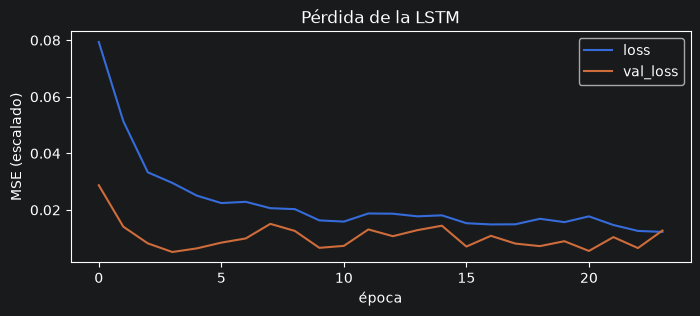

In [30]:
losses_lstm = pd.DataFrame(modelo_lstm.history.history)
print("Épocas entrenadas:", len(losses_lstm),
      "| mejor época (la que se guarda):", int(losses_lstm["val_loss"].idxmin()) + 1)

losses_lstm.plot(figsize=(8, 3), title="Pérdida de la LSTM")
plt.xlabel("época")
plt.ylabel("MSE (escalado)")
plt.show()

## 10.2 Comparación en validación: SimpleRNN contra LSTM

El modelo que usará la app se elige con **validación**, no con test. Entrenamos las dos redes con las mismas 5 semillas de la sección 9.1, porque con una sola corrida el resultado depende de la suerte.

In [31]:
filas = []
for tipo in ["SimpleRNN", "LSTM"]:
    for semilla in [101, 1, 2, 3, 4]:
        modelo, historia_semilla, _, _, validacion, test = entrenar(columnas_finales, semilla, tipo)
        prediccion_validacion = a_casos(modelo.predict(validacion, verbose=0))
        prediccion = a_casos(modelo.predict(test, verbose=0))
        filas.append({"modelo": tipo, "semilla": semilla,
                      "mejor_epoca": int(np.argmin(historia_semilla.history["val_loss"])) + 1,
                      "RMSE_validacion": rmse(casos_reales[filas_validacion], prediccion_validacion),
                      "RMSE_test": rmse(real_test, prediccion), "MAE_test": mae(real_test, prediccion)})

comparacion_modelos = pd.DataFrame(filas)
print(comparacion_modelos.pivot(index="semilla", columns="modelo", values="RMSE_validacion").round(1))
print(comparacion_modelos.groupby("modelo")["RMSE_validacion"].mean().round(1))
print("Mejor época de cada corrida (EarlyStopping):")
print(comparacion_modelos.pivot(index="semilla", columns="modelo", values="mejor_epoca"))

modelo   LSTM  SimpleRNN
semilla                 
1        36.7       42.5
2        40.1       37.2
3        43.2       38.0
4        45.6       42.0
101      40.3       35.1
modelo
LSTM         41.2
SimpleRNN    39.0
Name: RMSE_validacion, dtype: float64
Mejor época de cada corrida (EarlyStopping):
modelo   LSTM  SimpleRNN
semilla                 
1          13         77
2          41         51
3          12         73
4          17         68
101         4         57


In [32]:
promedio_validacion = comparacion_modelos.groupby("modelo")["RMSE_validacion"].mean()
modelo_para_app = promedio_validacion.idxmin()
print("Modelo con menor error promedio en validación:", modelo_para_app)

Modelo con menor error promedio en validación: SimpleRNN


**Resultado:** la SimpleRNN tiene menor error en validación en 4 de las 5 semillas (promedio de 39.0 contra 41.2). La LSTM solo gana con la semilla 1.

Además, la LSTM se detiene mucho antes: su mejor época va de la 4 a la 41, contra la 51 a la 77 de la SimpleRNN.

**Para la app se mantiene la SimpleRNN** (`rnn_simple.h5`), que es la que ya usan la API y la app. La LSTM igual se evalúa y se guarda, porque el enunciado pide reportar el RMSE de las dos.

# 11. Evaluación en test: SimpleRNN contra LSTM

Igual que en la sección 9: casos reales, las 101 ventanas completas del test y los mismos dos controles (baseline estacional y persistencia). Los dos modelos son los de la semilla 101.

In [33]:
prediccion_lstm = a_casos(modelo_lstm.predict(gen_test, verbose=0))

pronosticos = {"SimpleRNN": prediccion_test, "LSTM": prediccion_lstm,
               "Baseline estacional": estacional, "Persistencia": persistencia}
tabla_final = pd.DataFrame({
    "RMSE": [rmse(real_test, p) for p in pronosticos.values()],
    "MAE": [mae(real_test, p) for p in pronosticos.values()],
}, index=pronosticos.keys()).round(1)
print(tabla_final)

print("Mejora sobre el baseline estacional (%):")
print((100 * (1 - tabla_final.loc[["SimpleRNN", "LSTM"]] / tabla_final.loc["Baseline estacional"])).round(1))

                      RMSE    MAE
SimpleRNN            260.2  174.9
LSTM                 494.2  334.3
Baseline estacional  638.3  455.7
Persistencia         215.8  141.3
Mejora sobre el baseline estacional (%):
           RMSE   MAE
SimpleRNN  59.2  61.6
LSTM       22.6  26.6


In [34]:
# Error según qué tan lejos es el pronóstico
pd.DataFrame({
    "RMSE_SimpleRNN": [rmse(real_test[:, h], prediccion_test[:, h]) for h in range(HORIZONTE)],
    "RMSE_LSTM": [rmse(real_test[:, h], prediccion_lstm[:, h]) for h in range(HORIZONTE)],
    "RMSE_persistencia": [rmse(real_test[:, h], persistencia[:, h]) for h in range(HORIZONTE)],
}, index=[f"semana +{h + 1}" for h in range(HORIZONTE)]).round(1)

,RMSE_SimpleRNN,RMSE_LSTM,RMSE_persistencia
semana +1,229.2,442.3,129.2
semana +2,219.5,483.1,189.7
semana +3,338.7,487.8,236.3
semana +4,235.3,556.6,278.7


In [35]:
# Error y sesgo por año (sesgo positivo: el pronóstico se queda corto)
pd.DataFrame([{
    "año": anio,
    "RMSE_SimpleRNN": rmse(real_test[anios == anio], prediccion_test[anios == anio]),
    "RMSE_LSTM": rmse(real_test[anios == anio], prediccion_lstm[anios == anio]),
    "sesgo_SimpleRNN": (real_test[anios == anio] - prediccion_test[anios == anio]).mean(),
    "sesgo_LSTM": (real_test[anios == anio] - prediccion_lstm[anios == anio]).mean(),
} for anio in [2023, 2024]]).set_index("año").round(1)

,RMSE_SimpleRNN,RMSE_LSTM,sesgo_SimpleRNN,sesgo_LSTM
año,,,,
2023,301.0,593.7,146.1,385.1
2024,206.1,353.0,85.9,251.9


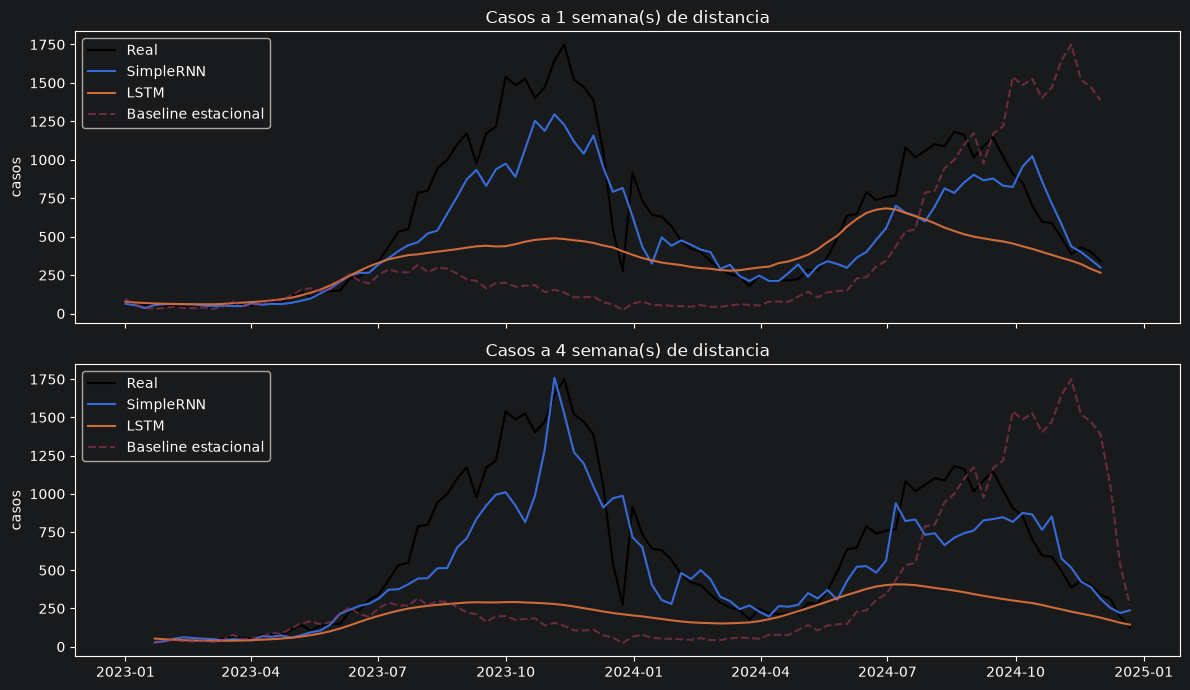

Pico del brote: 2023-11-12 | casos reales: 1749
Pronóstico a 1 semana -> SimpleRNN: 1227  LSTM: 484


In [36]:
# Pronóstico contra lo real: a 1 semana y a 4 semanas
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eje, h in zip(ejes, [0, 3]):
    fechas_objetivo = fechas[filas_test + h]
    eje.plot(fechas_objetivo, real_test[:, h], label="Real", color="black")
    eje.plot(fechas_objetivo, prediccion_test[:, h], label="SimpleRNN")
    eje.plot(fechas_objetivo, prediccion_lstm[:, h], label="LSTM")
    eje.plot(fechas_objetivo, estacional[:, h], label="Baseline estacional", linestyle="--", alpha=0.6)
    eje.set_title(f"Casos a {h + 1} semana(s) de distancia")
    eje.set_ylabel("casos")
    eje.legend()
plt.tight_layout()
plt.show()

print("Pico del brote:", fechas[filas_test[pico]].date(), "| casos reales:", int(real_test[pico, 0]))
print("Pronóstico a 1 semana -> SimpleRNN:", int(prediccion_test[pico, 0]), " LSTM:", int(prediccion_lstm[pico, 0]))

## 11.1 ¿Qué tan estable es cada modelo?

Resultados en test de las 5 semillas de la sección 10.2. No se elige nada con esta tabla: solo muestra cuánto cambia cada red de una corrida a otra.

In [37]:
comparacion_modelos.groupby("modelo")[["RMSE_test", "MAE_test"]].agg(["mean", "min", "max"]).round(1)

RMSE_test               MAE_test              
               mean    min    max     mean    min    max
modelo                                                  
LSTM          319.2  232.5  494.2    208.9  158.7  334.3
SimpleRNN     256.1  225.6  319.8    166.1  148.6  195.7

## 11.2 Guardar la LSTM

Se guarda con el mismo formato que la SimpleRNN. Usa los mismos escaladores y columnas, así que la app puede cargar cualquiera de los dos modelos con el mismo código.

In [38]:
modelo_lstm.save("../models/rnn_lstm.h5")
joblib.dump({"columnas": columnas_finales, "escalador_X": escalador_X, "escalador_y": escalador_y,
             "ventana": VENTANA, "horizonte": HORIZONTE}, "../models/rnn_lstm_preprocesado.pkl")
print(os.listdir("../models"))

['.gitkeep', 'rnn_lstm.h5', 'rnn_lstm_preprocesado.pkl', 'rnn_simple.h5', 'rnn_simple_preprocesado.pkl']


## 11.3 Ejemplo de uso para la app

Igual que en 9.3, pero con los archivos de la LSTM.

In [39]:
modelo = load_model("../models/rnn_lstm.h5", compile=False)
pre = joblib.load("../models/rnn_lstm_preprocesado.pkl")

semanas = df[pre["columnas"]].iloc[fin - pre["ventana"]:fin].values
entrada = pre["escalador_X"].transform(semanas)[np.newaxis, ...]
salida = modelo.predict(entrada, verbose=0)
pronostico = np.expm1(pre["escalador_y"].inverse_transform(salida.reshape(-1, 1))).ravel().clip(min=0)

print("Pronóstico desde", df.index[fin].date(), ":", pronostico.round().astype(int))
print("Casos reales de esas semanas:", df["casos_dengue"].values[fin:fin + 4])
print("casos_pred_4sem para la ANN:", int(pronostico.sum()))

Pronóstico desde 2024-12-01 : [265 219 207 144]
Casos reales de esas semanas: [340 312 197 125]
casos_pred_4sem para la ANN: 835


# 12. Conclusiones: SimpleRNN contra LSTM

- **Las dos superan al baseline estacional**, como pide el enunciado. En test, la SimpleRNN tiene un RMSE de 260.2 (59 % menos que el baseline, 638.3) y la LSTM de 494.2 (23 % menos). En MAE: 174.9 y 334.3 contra 455.7.
- **La LSTM no mejoró a la SimpleRNN con estos datos.** Fue peor en validación (4 de 5 semillas) y en test: con las 5 semillas, su RMSE promedio es 319.2 (de 232.5 a 494.2) contra 256.1 de la SimpleRNN (de 225.6 a 319.8). Además cambia mucho más de una semilla a otra.
- **Por qué:**
  - **Pocos datos para una red grande.** La LSTM tiene 30,980 pesos y la SimpleRNN 1,412, con solo 381 ventanas de entrenamiento.
  - **El año de validación no tuvo brote.** En 2022 el máximo fue de 316 casos por semana, contra 1,749 en 2023 y 1,182 en 2024. Con una validación así, la `val_loss` premia pronósticos suaves, y EarlyStopping detiene a la LSTM antes de que aprenda a seguir los brotes: su mejor época va de la 4 a la 41, contra la 51 a la 77 de la SimpleRNN.
  - **La semilla 101 se detuvo en la época 4**, la más temprana, y por eso es también la peor LSTM de las 5 en test (RMSE de 494.2). No se cambió la semilla por eso: elegirla mirando el test sería hacer trampa. Su curva es casi plana en 2023 y 2024: en el pico (12 de noviembre de 2023) pronosticó 484 casos a una semana, contra 1,749 reales; la SimpleRNN pronosticó 1,227.
  - **Las dos subestiman los brotes**, pero la LSTM mucho más: en 2023 se queda corta por 385 casos por semana en promedio, y la SimpleRNN por 146.
- **Ninguna supera a la persistencia** (copiar la última semana, RMSE de 215.8). La SimpleRNN solo le gana a 4 semanas de distancia.
- **Decisión:** la app y la API siguen con la SimpleRNN. La LSTM queda guardada en `models/rnn_lstm.h5` como el modelo principal que pide el enunciado, con su resultado documentado.
- **Cómo se podría mejorar** (no se probó por falta de tiempo): validar con un año que tenga brote, para que EarlyStopping no premie pronósticos planos; usar una LSTM más pequeña o más datos (por ejemplo, la serie por provincia); y medir el error sobre todo en las semanas de brote, que son las que importan para las alertas.